# PathSnap: Module 1 — Dataset Understanding & Exploratory Data Analysis (EDA)
**Course:** UE24CS352A - Machine Learning | PES University (RR Campus)  
**Hackathon Phase:** Pre-Lunch Evaluation & Exploratory Analysis

This notebook demonstrates:
1. Loading raw GPS trajectories (`.track`), road network intersections (`.nodes`), segments (`.arcs`), and reference routes (`.route`).
2. Global dataset inventory statistics across the 80 training and 10 student-test trips.
3. Coordinate validation and sampling interval ($\Delta t$) distribution.
4. Physical road-network connectivity analysis of the ground-truth route sequence.
5. Empirical validation of the monotonic polyline alignment algorithm (recovering ground-truth observation labels).
6. Interactive Folium map generation visualizing GPS noise against the physical road network.


In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import folium

# Robustly resolve PROJECT_ROOT whether run from repo root or notebooks/
if os.path.exists("Student folder"):
    PROJECT_ROOT = "."
elif os.path.exists("../Student folder"):
    PROJECT_ROOT = ".."
else:
    PROJECT_ROOT = os.path.abspath(".")

sys.path.insert(0, PROJECT_ROOT)
from src.data.loader import load_trip, get_available_trip_ids
from src.features.spatial import LocalMetricProjector, point_to_segment_distances
from src.features.alignment import align_route_to_observations

print(f"Project Root: {PROJECT_ROOT}")
print("Imports successful! Python environment ready.")


Project Root: ..
Imports successful! Python environment ready.


In [2]:
trip_id = "00000001"
trip_dir = os.path.join(PROJECT_ROOT, f"Student folder/train/{trip_id}")
trip = load_trip(trip_dir, trip_id, load_route=True)

print(f"=== Trip {trip_id} Overview ===")
print(f"Track observations (.track): {len(trip.track)} rows")
print(f"Road network nodes (.nodes): {len(trip.nodes)} rows")
print(f"Road network arcs (.arcs):   {len(trip.arcs)} rows")
print(f"Reference route (.route):    {len(trip.route)} traversed arcs")

display(trip.track.head())


=== Trip 00000001 Overview ===
Track observations (.track): 1315 rows
Road network nodes (.nodes): 88809 rows
Road network arcs (.arcs):   165790 rows
Reference route (.route):    525 traversed arcs


,lon,lat,t
0,8.595203,49.844053,1.0
1,8.595294,49.844441,2.0
2,8.595352,49.844883,3.0
3,8.595390,49.845379,4.0
4,8.595587,49.845750,5.0


In [3]:
inv_path = os.path.join(PROJECT_ROOT, "artifacts/results/dataset_inventory.csv")
if os.path.exists(inv_path):
    inv_df = pd.read_csv(inv_path)
else:
    from src.data.inventory import compute_inventory
    inv_df = compute_inventory(os.path.join(PROJECT_ROOT, "Student folder"))

print(f"Total trips inventoried: {len(inv_df)}")
summary = inv_df.groupby("partition").agg(
    trip_count=("trip_id", "count"),
    total_track_points=("track_points", "sum"),
    mean_track_points=("track_points", "mean"),
    mean_road_arcs=("road_arcs", "mean"),
    mean_dt_1s_pct=("pct_dt_1s", "mean"),
    mean_route_continuity=("route_continuity_pct", "mean"),
)
display(summary)


Total trips inventoried: 90


,trip_count,total_track_points,mean_track_points,mean_road_arcs,mean_dt_1s_pct,mean_route_continuity
partition,,,,,,
student_test,10,19160,1916.0000,18504.1,98.199000,99.97300
train,80,208417,2605.2125,48461.3,93.829625,99.93475


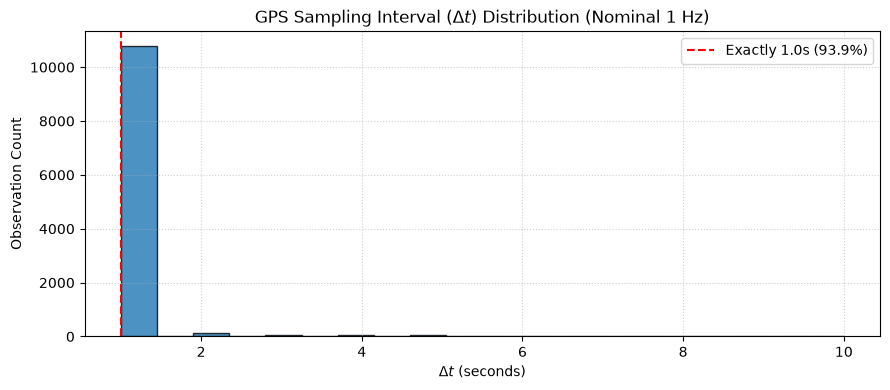

In [4]:
# Analyze sampling intervals for sample trips
dt_list = []
for tid in ["00000001", "00000002", "00000003", "00000004", "00000005"]:
    t_df = load_trip(os.path.join(PROJECT_ROOT, f"Student folder/train/{tid}"), tid, load_route=False).track
    dt_list.extend(np.diff(t_df['t'].values))

dt_arr = np.array(dt_list)
plt.figure(figsize=(9, 4))
plt.hist(dt_arr[dt_arr <= 10], bins=20, color="#1f77b4", edgecolor="black", alpha=0.8)
plt.title(r"GPS Sampling Interval ($\Delta t$) Distribution (Nominal 1 Hz)")
plt.xlabel(r"$\Delta t$ (seconds)")
plt.ylabel("Observation Count")
plt.axvline(1.0, color="red", linestyle="--", label=f"Exactly 1.0s ({np.mean(dt_arr == 1.0)*100:.1f}%)")
plt.legend()
plt.grid(True, linestyle=":", alpha=0.6)
plt.tight_layout()
plt.show()


In [5]:
# Check route arc sequence connectivity in road network
route_arcs = trip.route
u_seq = trip.arcs.iloc[route_arcs]["u"].values
v_seq = trip.arcs.iloc[route_arcs]["v"].values

connected = np.sum(v_seq[:-1] == u_seq[1:])
total_transitions = len(route_arcs) - 1
print(f"Trip {trip_id} Route Connectivity: {connected}/{total_transitions} ({connected/total_transitions*100:.2f}%)")
print("Conclusion: .route represents an exact continuous physical path along the road network graph.")


Trip 00000001 Route Connectivity: 524/524 (100.00%)
Conclusion: .route represents an exact continuous physical path along the road network graph.


Alignment complete for all 1315 observations!
Median perpendicular deviation from true arc: 4.30 meters
90th percentile deviation:                     10.22 meters
95th percentile deviation:                     12.36 meters
Maximum deviation:                             27.21 meters


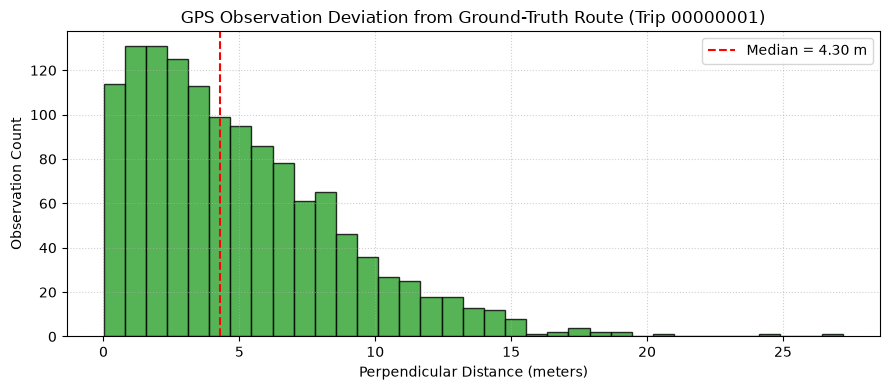

In [6]:
center_lon = trip.track["lon"].mean()
center_lat = trip.track["lat"].mean()
projector = LocalMetricProjector(center_lon, center_lat)

ref_arcs, ref_dists = align_route_to_observations(trip, projector)

print(f"Alignment complete for all {len(ref_arcs)} observations!")
print(f"Median perpendicular deviation from true arc: {np.median(ref_dists):.2f} meters")
print(f"90th percentile deviation:                     {np.percentile(ref_dists, 90):.2f} meters")
print(f"95th percentile deviation:                     {np.percentile(ref_dists, 95):.2f} meters")
print(f"Maximum deviation:                             {np.max(ref_dists):.2f} meters")

plt.figure(figsize=(9, 4))
plt.hist(ref_dists, bins=35, color="#2ca02c", edgecolor="black", alpha=0.8)
plt.title(f"GPS Observation Deviation from Ground-Truth Route (Trip {trip_id})")
plt.xlabel("Perpendicular Distance (meters)")
plt.ylabel("Observation Count")
plt.axvline(np.median(ref_dists), color="red", linestyle="--", label=f"Median = {np.median(ref_dists):.2f} m")
plt.legend()
plt.grid(True, linestyle=":", alpha=0.6)
plt.tight_layout()
plt.show()


In [7]:
# Generate interactive Folium map for first 120 points
sample_track = trip.track.iloc[:120]
start_lat, start_lon = sample_track["lat"].iloc[0], sample_track["lon"].iloc[0]

m = folium.Map(location=[start_lat, start_lon], zoom_start=15, tiles="CartoDB positron")

# 1. Raw GPS points
for _, row in sample_track.iterrows():
    folium.CircleMarker(
        location=[row["lat"], row["lon"]],
        radius=3,
        color="#1f77b4",
        fill=True,
        fill_opacity=0.7,
        tooltip=f"t={row['t']:.0f}s"
    ).add_to(m)

# 2. Ground-truth route polyline
route_coords = []
for arc_id in route_arcs[:40]:
    u = trip.arcs.iloc[arc_id]["u"]
    v = trip.arcs.iloc[arc_id]["v"]
    p1 = [trip.nodes.iloc[u]["lat"], trip.nodes.iloc[u]["lon"]]
    p2 = [trip.nodes.iloc[v]["lat"], trip.nodes.iloc[v]["lon"]]
    route_coords.extend([p1, p2])

folium.PolyLine(
    locations=route_coords,
    color="#2ca02c",
    weight=4,
    opacity=0.8,
    tooltip="Ground-Truth Route"
).add_to(m)

out_folium = os.path.join(PROJECT_ROOT, "artifacts/plots/sample_trip_folium.html")
os.makedirs(os.path.dirname(out_folium), exist_ok=True)
m.save(out_folium)
print(f"Saved Folium map to {out_folium}")
display(m)


Saved Folium map to ../artifacts/plots/sample_trip_folium.html


/run/media/cow/D/college/sem5/ml/mlhack/.venv/lib/python3.14/site-packages/folium/raster_layers.py:129: UserWarning: CartoDB tiles now require an API key. Please provide one to continue using the tiles. You can request the key at https://carto.com/basemaps/apikey/.
  tiles = tiles.build_url(fill_subdomain=False, scale_factor="{r}")  # type: ignore
